# Tunisian Tax Fraud Detection — a beginner's walkthrough

**Goal:** predict `target`, how much a taxpayer's tax liability had to be adjusted after inspection. A big predicted adjustment = a taxpayer worth auditing.

This notebook follows the standard machine-learning workflow:

1. Load the data
2. Understand the data (exploration)
3. Prepare the features
4. Choose a fair way to measure the model (validation)
5. Build a baseline, then a real model
6. Understand what the model learned
7. Predict on new data and write a submission

Run each cell from top to bottom (Shift + Enter). Put `Train.csv` (and `Test.csv`, if you have it) in the same folder as this notebook.

You'll need: `pip install pandas numpy scikit-learn lightgbm matplotlib`

## Step 1 — Load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.model_selection import GroupKFold
from sklearn.metrics import mean_squared_error, roc_auc_score
import warnings; warnings.filterwarnings('ignore')

In [2]:
train = pd.read_csv('Train.csv')
print('Rows, columns:', train.shape)
train.head()

Rows, columns: (21295, 121)


,BCT_CODBUR,CTR_MATFIS,CTR_CATEGO_X,FJU_CODFJU,CTR_CESSAT,ACT_CODACT,CTR_OBLDIR,CTR_OBLACP,CTR_OBLRES,CTR_OBLFOP,...,target,FAC_MNTPRI_F,FAC_MFODEC_F,FAC_MNTDCO_F,FAC_MNTTVA_F,FAC_MNTPRI_C,FAC_MFODEC_C,FAC_MNTDCO_C,FAC_MNTTVA_C,id
0,44,6210,C,99,0,3707,4,2,2,2,...,16.639203,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,train_id17437
1,401,14383,M,22,0,6105,4,2,2,2,...,17.827703,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,train_id5086
2,243,11555,M,23,0,5751,4,2,2,2,...,15.473503,25387000.0,0.0,0.0,4571280.0,NaN,NaN,NaN,NaN,train_id1443
3,72,6175,C,99,0,4402,4,2,2,2,...,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,train_id15469
4,42,1417,M,23,0,6302,4,2,2,2,...,14.286244,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,train_id14368


## Step 2 — Understand the data

Before modelling, always look at **the thing you're predicting** (the target).

count    21295.000000
mean        11.780084
std          7.085772
min          0.000000
25%          0.000000
50%         14.981121
75%         16.625623
max         23.591334
Name: target, dtype: float64

Share of rows where target = 0: 0.254


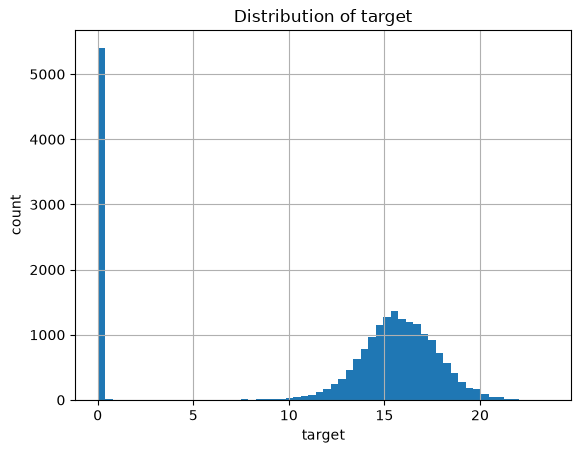

In [3]:
print(train['target'].describe())
print('\nShare of rows where target = 0:', round((train['target'] == 0).mean(), 3))

train['target'].hist(bins=60)
plt.title('Distribution of target'); plt.xlabel('target'); plt.ylabel('count'); plt.show()

**What this tells us**

- About **25% of taxpayers have target = 0** — no adjustment was needed (no fraud found).
- The rest sit between roughly 10 and 23. Money amounts don't naturally look like this: the organisers have almost certainly applied a **log transform** (`log(1 + amount)`). That's helpful — it squashes huge amounts so a few giant cases don't dominate the model.
- So this is a **regression** problem (predict a number), not a yes/no classification. A higher prediction means "more likely to owe a large adjustment".

In [4]:
print('Records per tax year:')
print(train['EXE_EXERCI'].value_counts().sort_index())
print('\nUnique row ids:', train['id'].nunique())
print('Unique taxpayers (CTR_MATFIS):', train['CTR_MATFIS'].nunique())

Records per tax year:
EXE_EXERCI
2013    6079
2014    5754
2015    4368
2016    3100
2017    1629
2018     365
Name: count, dtype: int64

Unique row ids: 21295
Unique taxpayers (CTR_MATFIS): 12387


**Important:** there are ~21,300 rows but only ~12,400 distinct taxpayers. The same taxpayer appears in several years. Keep this in mind — it matters a lot in Step 4.

Columns with >50% missing values: 30


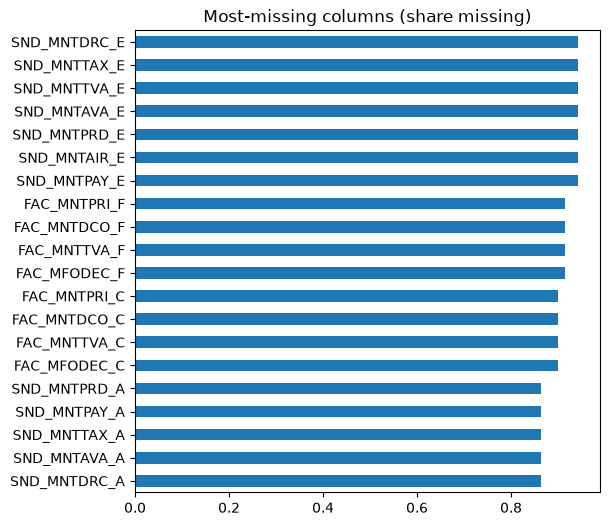

In [5]:
missing = train.isna().mean().sort_values(ascending=False)
print('Columns with >50% missing values:', (missing > 0.5).sum())
missing.head(20).plot.barh(figsize=(6,6)); plt.title('Most-missing columns (share missing)'); plt.gca().invert_yaxis(); plt.show()

Many columns are mostly empty (e.g. invoice `FAC_*` and some `SND_*` columns are >90% missing). That's normal for tax data — not every taxpayer files every form. We will **not** delete them: the *fact* that a form is missing can itself be informative. The model we use (LightGBM) handles missing values automatically.

## Step 3 — Prepare the features

- `target` is what we predict, so it's removed from the inputs.
- `id` is just a row label, and `CTR_MATFIS` is a taxpayer ID — we remove both so the model can't memorise specific people.
- `CTR_CATEGO_X` is text (M, C, P, N), so we mark it as a *category*.
- We add one simple engineered feature: how many fields are missing for each row.

In [6]:
def make_features(df):
    X = df.drop(columns=[c for c in ['target', 'id', 'CTR_MATFIS'] if c in df.columns]).copy()
    X['CTR_CATEGO_X'] = X['CTR_CATEGO_X'].astype(pd.CategoricalDtype(['C', 'M', 'N', 'P']))
    X['n_missing'] = df.isna().sum(axis=1)
    return X

X = make_features(train)
y = train['target'].values
groups = train['CTR_MATFIS'].values   # used only to split data fairly
print('Feature matrix:', X.shape)

Feature matrix: (21295, 119)


## Step 4 — Measure the model fairly (validation)

We need to estimate how well the model will do on taxpayers it has **never seen**.

**Cross-validation:** split the data into 5 parts ("folds"). Train on 4, test on the 5th, rotate 5 times, average the scores.

**The trap:** if the same taxpayer's 2014 return is in training and their 2015 return is in testing, the model gets an unfair peek and the score looks better than reality. So we use **GroupKFold**, which keeps every taxpayer entirely within one fold.

**Metric — RMSE** (root mean squared error): the typical size of the prediction error. Lower is better.

In [7]:
def rmse(a, b):
    return np.sqrt(mean_squared_error(a, b))

baseline = rmse(y, np.full_like(y, y.mean()))
print(f'Baseline RMSE (always predict the average): {baseline:.3f}')

Baseline RMSE (always predict the average): 7.086


That's our **baseline**: a "model" that ignores the data. Any real model must beat it.

## Step 5 — Train a LightGBM model

**LightGBM** builds many small decision trees, each one correcting the errors of the previous ones ("gradient boosting"). It's the go-to choice for tabular data like this: fast, handles missing values, no scaling needed.

**Early stopping:** we let it add trees until the validation score stops improving for 100 rounds, which prevents *overfitting* (memorising training data instead of learning patterns).

In [8]:
params = dict(n_estimators=3000, learning_rate=0.03, num_leaves=31,
              min_child_samples=30, subsample=0.8, subsample_freq=1,
              colsample_bytree=0.7, random_state=42, verbose=-1)

oof = np.zeros(len(y))            # 'out-of-fold' predictions
importance = np.zeros(X.shape[1])
best_iters = []

for fold, (tr, va) in enumerate(GroupKFold(n_splits=5).split(X, y, groups), 1):
    model = lgb.LGBMRegressor(**params)
    model.fit(X.iloc[tr], y[tr], eval_set=[(X.iloc[va], y[va])],
              callbacks=[lgb.early_stopping(100, verbose=False)])
    oof[va] = model.predict(X.iloc[va])
    importance += model.feature_importances_
    best_iters.append(model.best_iteration_)
    print(f'Fold {fold}: RMSE = {rmse(y[va], oof[va]):.3f}  (trees used: {model.best_iteration_})')

oof = np.clip(oof, 0, None)   # target can't be negative
print(f'\nOverall CV RMSE: {rmse(y, oof):.3f}   vs baseline {baseline:.3f}')
print(f'Fraud-ranking AUC (target > 0): {roc_auc_score(y > 0, oof):.3f}')

Fold 1: RMSE = 5.992  (trees used: 439)
Fold 2: RMSE = 5.959  (trees used: 363)
Fold 3: RMSE = 6.101  (trees used: 397)
Fold 4: RMSE = 6.036  (trees used: 228)
Fold 5: RMSE = 5.936  (trees used: 770)

Overall CV RMSE: 6.004   vs baseline 7.086
Fraud-ranking AUC (target > 0): 0.831


**How to read this**

- RMSE drops from about **7.09 → 6.00**. The model has genuinely learned something.
- **AUC ≈ 0.83**: if you pick one taxpayer who *did* need an adjustment and one who didn't, the model scores the right one higher about 83% of the time (0.5 = coin flip, 1.0 = perfect). For an audit office, that's the practical value: **rank taxpayers and inspect the top of the list first.**
- The 5 fold scores are close together, so the estimate is stable.

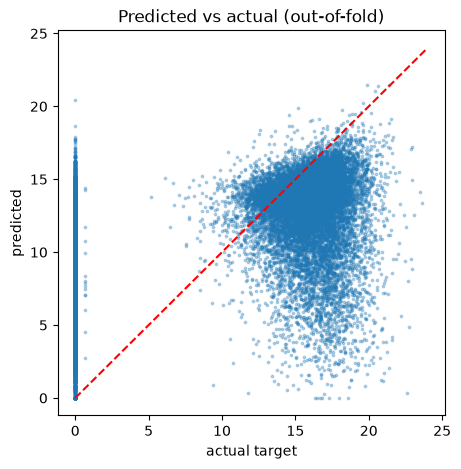

In [9]:
plt.figure(figsize=(5,5))
plt.scatter(y, oof, s=3, alpha=0.3)
plt.plot([0, 24], [0, 24], 'r--')
plt.xlabel('actual target'); plt.ylabel('predicted'); plt.title('Predicted vs actual (out-of-fold)')
plt.show()

Predictions crowd toward the middle — the model is unsure about many taxpayers, especially the zeros. That's expected with noisy real-world fraud data, and it's where improvements come from (see Step 8).

## Step 6 — What did the model learn?

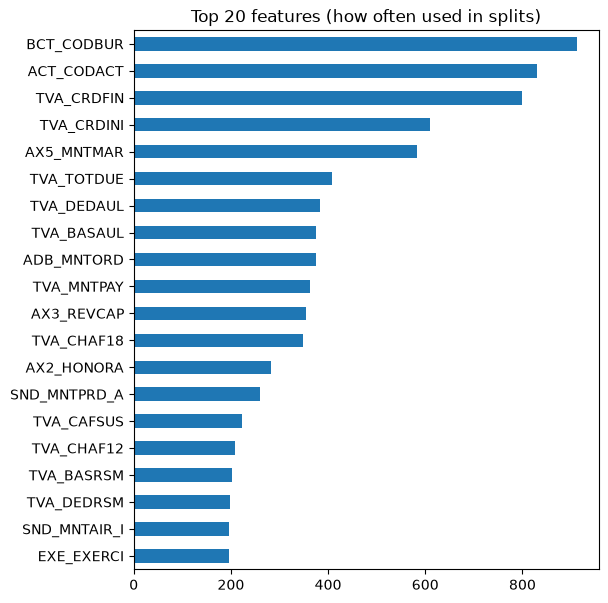

In [10]:
imp = pd.Series(importance / 5, index=X.columns).sort_values(ascending=False)
imp.head(20).plot.barh(figsize=(6,7)); plt.gca().invert_yaxis()
plt.title('Top 20 features (how often used in splits)'); plt.show()

The most-used signals are the **tax office** (`BCT_CODBUR`), **business activity code** (`ACT_CODACT`), **VAT credit at the start/end of the period** (`TVA_CRDINI`, `TVA_CRDFIN`), and **declared margin** (`AX5_MNTMAR`). That makes intuitive sense: carrying large VAT credits or reporting unusual margins for your sector are classic red flags for under-reporting.

⚠️ Note: `BCT_CODBUR` and `ACT_CODACT` are numeric codes, not real quantities. Trees can still split on them, but treating them as categories is a good experiment to try.

## Step 7 — Train on all data and predict on the test set

For the final model we train on **all** training rows, using roughly the average number of trees found during cross-validation.

In [11]:
final_model = lgb.LGBMRegressor(**{**params, 'n_estimators': int(np.mean(best_iters) * 1.1)})
final_model.fit(X, y)

import os
if os.path.exists('Test.csv'):
    test = pd.read_csv('Test.csv')
    preds = np.clip(final_model.predict(make_features(test)[X.columns]), 0, None)
    submission = pd.DataFrame({'id': test['id'], 'target': preds})
    submission.to_csv('submission.csv', index=False)
    print('Saved submission.csv'); display(submission.head())
else:
    print('No Test.csv found — put it next to this notebook and re-run this cell.')

Saved submission.csv


,id,target
0,test_id1120,16.388778
1,test_id1680,14.799121
2,test_id1063,11.900186
3,test_id3731,15.699152
4,test_id9766,14.274905


## Step 8 — Ideas to improve (try one at a time, check the CV score)

1. **Treat codes as categories:** convert `BCT_CODBUR`, `ACT_CODACT`, `FJU_CODFJU` to `category` dtype.
2. **Ratio features:** e.g. `TVA_TOTDUE / TVA_CHAF18`, deductions ÷ turnover, `TVA_CRDFIN - TVA_CRDINI`. Fraud often shows up as *unusual proportions*, not unusual totals.
3. **Peer comparison:** how a taxpayer's margin compares to the average for the same activity code.
4. **History features:** each taxpayer's values in their previous year (the data has up to 6 years per taxpayer).
5. **Two-stage model:** a classifier for "will target be 0?" × a regressor for "how much, if not 0?".
6. **Tune hyperparameters** (`num_leaves`, `learning_rate`, `min_child_samples`) — but only after features.
7. **Average several models** (different seeds or LightGBM + CatBoost).

**Golden rule:** change one thing, re-run Step 5, keep it only if CV RMSE goes down.